In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# Load the dataset directly from the UCI repository URL
FILE = "https://archive.ics.uci.edu/ml/machine-learning-databases/autos/imports-85.data"

columns = [
    "symboling", "normalized_losses", "make", "fuel_type", "aspiration",
    "num_of_doors", "body_style", "drive_wheels", "engine_location",
    "wheel_base", "length", "width", "height", "curb_weight", "engine_type",
    "num_of_cylinders", "engine_size", "fuel_system", "bore", "stroke",
    "compression_ratio", "horsepower", "peak_rpm", "city_mpg", "highway_mpg",
    "price",
]

In [49]:
# The file has no header row and uses '?' for missing values.
df = pd.read_csv(FILE, header=None, names=columns, na_values="?")

# Columns that contain '?' are read as text, so make sure they are numeric.
for col in ["normalized_losses", "bore", "stroke", "horsepower", "peak_rpm", "price"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")


First look at the data

In [50]:
print("HEAD");  print(df.head())
print("\nTAIL"); print(df.tail())
print("\nSHAPE:", df.shape)
print("\nINFO");  df.info()
print("\nDESCRIBE"); print(df.describe())

HEAD
   symboling  normalized_losses         make fuel_type aspiration num_of_doors   body_style drive_wheels engine_location  wheel_base  length  width  height  curb_weight engine_type num_of_cylinders  \
0          3                NaN  alfa-romero       gas        std          two  convertible          rwd           front        88.6   168.8   64.1    48.8         2548        dohc             four   
1          3                NaN  alfa-romero       gas        std          two  convertible          rwd           front        88.6   168.8   64.1    48.8         2548        dohc             four   
2          1                NaN  alfa-romero       gas        std          two    hatchback          rwd           front        94.5   171.2   65.5    52.4         2823        ohcv              six   
3          2              164.0         audi       gas        std         four        sedan          fwd           front        99.8   176.6   66.2    54.3         2337         ohc           

Question 1: Which manufacturers appear most often?

In [51]:
make_counts = df["make"].value_counts()
print(make_counts)

make
toyota           32
nissan           18
mazda            17
mitsubishi       13
honda            13
subaru           12
volkswagen       12
volvo            11
peugot           11
dodge             9
mercedes-benz     8
bmw               8
audi              7
plymouth          7
saab              6
porsche           5
isuzu             4
alfa-romero       3
chevrolet         3
jaguar            3
renault           2
mercury           1
Name: count, dtype: int64


Question 2: Average, minimum and maximum price (NumPy array)

In [52]:
prices = df["price"].dropna().to_numpy()      # NumPy array of prices
print("Average price:", round(np.mean(prices), 2))
print("Minimum price:", np.min(prices))
print("Maximum price:", np.max(prices))
print("Median price :", np.median(prices))
print("Std deviation:", round(np.std(prices, ddof=1), 2))


Average price: 13207.13
Minimum price: 5118.0
Maximum price: 45400.0
Median price : 10295.0
Std deviation: 7947.07


# More NumPy statistics on other numeric columns

In [53]:
horsepower = df["horsepower"].dropna().to_numpy()
engine_size = df["engine_size"].to_numpy()
print("\nHorsepower  mean/min/max:", round(np.mean(horsepower), 1), np.min(horsepower), np.max(horsepower))
print("Engine size mean/min/max:", round(np.mean(engine_size), 1), np.min(engine_size), np.max(engine_size))



Horsepower  mean/min/max: 104.3 48.0 288.0
Engine size mean/min/max: 126.9 61 326


Question 3: Which body style has the highest average price?

In [54]:
body_price = (df.groupby("body_style")["price"]
                .agg(["mean", "count"]
                ).sort_values("mean", ascending=False)
                .round(2))
print(body_price)
print("\nHighest average price:", body_price.index[0])

                 mean  count
body_style                  
hardtop      22208.50      8
convertible  21890.50      6
sedan        14459.76     94
wagon        12371.96     25
hatchback     9957.44     68

Highest average price: hardtop


Question 4: Average engine size by fuel type

In [55]:
fuel_engine = (df.groupby("fuel_type")["engine_size"]
                 .agg(["mean", "count"]
                 ).round(2))
print(fuel_engine)


             mean  count
fuel_type               
diesel     135.70     20
gas        125.96    185


Question 5:Missing values and duplicates

In [56]:
missing = df.isnull().sum()
print("Columns with missing values:")
print(missing[missing > 0].sort_values(ascending=False))
print("\nDuplicate rows:", df.duplicated().sum())


Columns with missing values:
normalized_losses    41
bore                  4
stroke                4
price                 4
num_of_doors          2
horsepower            2
peak_rpm              2
dtype: int64

Duplicate rows: 0


Question 6: 10 most expensive cars

In [57]:
top10 = (df.sort_values("price", ascending=False)
           [["make", "body_style", "fuel_type", "engine_size", "horsepower", "price"]]
           .head(10))
print(top10.to_string(index=False))


         make  body_style fuel_type  engine_size  horsepower   price
mercedes-benz     hardtop       gas          304       184.0 45400.0
          bmw       sedan       gas          209       182.0 41315.0
mercedes-benz       sedan       gas          308       184.0 40960.0
      porsche convertible       gas          194       207.0 37028.0
          bmw       sedan       gas          209       182.0 36880.0
       jaguar       sedan       gas          326       262.0 36000.0
       jaguar       sedan       gas          258       176.0 35550.0
mercedes-benz convertible       gas          234       155.0 35056.0
mercedes-benz       sedan       gas          234       155.0 34184.0
      porsche     hardtop       gas          194       207.0 34028.0


Filtering example: cars priced above the 90th percentile

In [58]:
p90 = np.percentile(prices, 90)
expensive = df[df["price"] > p90]
print(f"\nCars priced above {p90:,.0f}: {len(expensive)}")
print(expensive["make"].value_counts())



Cars priced above 22,470: 20
make
mercedes-benz    8
bmw              4
porsche          3
jaguar           3
audi             1
volvo            1
Name: count, dtype: int64


Chart 1: manufacturer counts

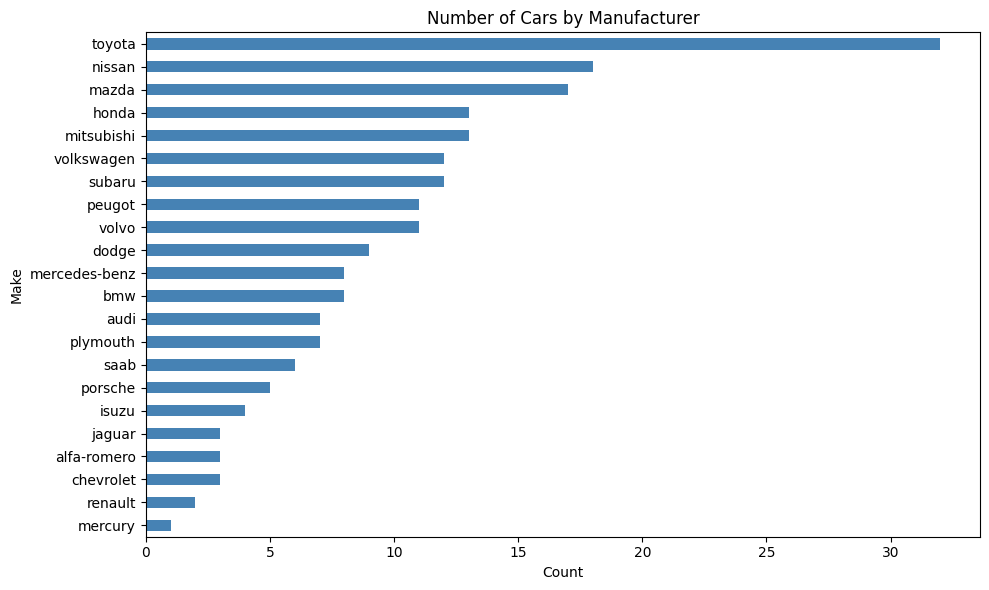

In [59]:
plt.figure(figsize=(10, 6))
make_counts.sort_values().plot(kind="barh", color="steelblue")
plt.title("Number of Cars by Manufacturer")
plt.xlabel("Count")
plt.ylabel("Make")
plt.tight_layout()
plt.savefig("manufacturer_counts.png", dpi=150)
plt.show()


Chart 2: price histogram

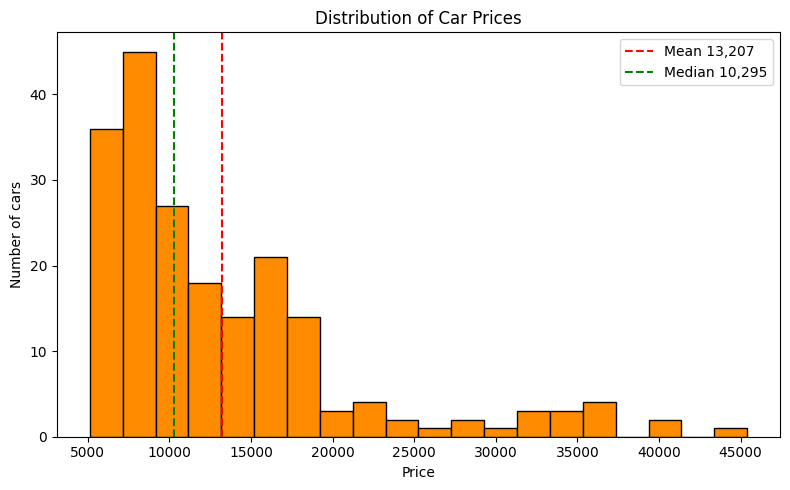

In [60]:
plt.figure(figsize=(8, 5))
plt.hist(prices, bins=20, color="darkorange", edgecolor="black")
plt.axvline(np.mean(prices), color="red", linestyle="--", label=f"Mean {np.mean(prices):,.0f}")
plt.axvline(np.median(prices), color="green", linestyle="--", label=f"Median {np.median(prices):,.0f}")
plt.title("Distribution of Car Prices")
plt.xlabel("Price")
plt.ylabel("Number of cars")
plt.legend()
plt.tight_layout()
plt.savefig("price_histogram.png", dpi=150)
plt.show()